# PathSnap: Module 2 — Candidate Generation & Feature Engineering
**Course:** UE24CS352A - Machine Learning | PES University (RR Campus)

This notebook demonstrates:
1. Spatial road-network indexing with multi-point `cKDTree` in local metric space.
2. Candidate road segment retrieval and Candidate Miss Rate evaluation (achieving **99.36% candidate recall**).
3. Vectorized feature construction for 9 geometric and kinematic features.
4. Feature distribution analysis and class separation between matching ($y=1$) and non-matching ($y=0$) candidate segments.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

if os.path.exists("Student folder"):
    PROJECT_ROOT = "."
elif os.path.exists("../Student folder"):
    PROJECT_ROOT = ".."
else:
    PROJECT_ROOT = os.path.abspath(".")

sys.path.insert(0, PROJECT_ROOT)
from src.data.loader import load_trip
from src.features.spatial import LocalMetricProjector
from src.features.candidates import RoadNetworkIndex
from src.features.build_features import extract_features_for_trip, FEATURE_COLUMNS

print("Candidate and Feature Engineering modules loaded.")


Candidate and Feature Engineering modules loaded.


In [2]:
trip_id = "00000001"
trip = load_trip(os.path.join(PROJECT_ROOT, f"Student folder/train/{trip_id}"), trip_id, load_route=True)

center_lon = trip.track["lon"].mean()
center_lat = trip.track["lat"].mean()
projector = LocalMetricProjector(center_lon, center_lat)

# Build road network spatial index
road_index = RoadNetworkIndex(trip, projector)

# Query candidates for first GPS observation
sample_pt = projector.forward(trip.track["lon"].iloc[0:1].values, trip.track["lat"].iloc[0:1].values)
cand_arcs, geom = road_index.get_candidates(sample_pt, k_pool=80, k_cand=8)

print(f"Top 8 Candidate Arcs for first observation:")
for rank, (arc_id, dist, length) in enumerate(zip(cand_arcs, geom["perp_dist"], geom["seg_length"])):
    print(f"  Rank {rank}: Arc ID = {arc_id:6d} | Perpendicular Dist = {dist:6.2f} m | Segment Length = {length:6.2f} m")


Top 8 Candidate Arcs for first observation:
  Rank 0: Arc ID =  64973 | Perpendicular Dist =   0.72 m | Segment Length = 293.23 m
  Rank 1: Arc ID = 117639 | Perpendicular Dist =  15.01 m | Segment Length = 1020.42 m
  Rank 2: Arc ID =   2641 | Perpendicular Dist =  32.20 m | Segment Length = 425.05 m
  Rank 3: Arc ID =  50652 | Perpendicular Dist =  92.29 m | Segment Length = 169.06 m
  Rank 4: Arc ID =  53932 | Perpendicular Dist =  92.29 m | Segment Length = 169.06 m
  Rank 5: Arc ID =  53933 | Perpendicular Dist =  95.91 m | Segment Length = 274.58 m
  Rank 6: Arc ID =  50653 | Perpendicular Dist =  95.91 m | Segment Length = 274.58 m
  Rank 7: Arc ID =  50585 | Perpendicular Dist =  95.91 m | Segment Length = 223.44 m


In [3]:
test_cand_summary = pd.read_csv(os.path.join(PROJECT_ROOT, "artifacts/results/student_test_candidate_summary.csv"))
print("=== Student-Test Candidate Retrieval Performance ===")
display(test_cand_summary)

mean_miss = test_cand_summary["miss_rate"].mean() * 100
mean_recall = 100.0 - mean_miss
print(f"Mean Candidate Miss Rate: {mean_miss:.2f}%")
print(f"Mean Candidate Recall:    {mean_recall:.2f}% (Over 99% of ground-truth arcs successfully captured)")


=== Student-Test Candidate Retrieval Performance ===


,trip_id,n_obs,valid_ref_count,miss_count,miss_rate
0,0,2503,2503,12,0.004794
1,7,1354,1354,0,0.000000
2,9,1049,1049,23,0.021926
3,40,2995,2995,1,0.000334
4,52,262,262,0,0.000000
5,56,3958,3958,40,0.010106
6,65,768,768,14,0.018229
7,76,1486,1486,10,0.006729
8,77,3911,3911,6,0.001534
9,91,874,874,0,0.000000


Mean Candidate Miss Rate: 0.64%
Mean Candidate Recall:    99.36% (Over 99% of ground-truth arcs successfully captured)


In [4]:
test_feats_path = os.path.join(PROJECT_ROOT, "artifacts/results/student_test_features.csv.gz")
test_df = pd.read_csv(test_feats_path)

print(f"Student Test Feature Table Shape: {test_df.shape}")
print(f"Extracted Feature Columns ({len(FEATURE_COLUMNS)} features): {FEATURE_COLUMNS}")
display(test_df.head(8))


Student Test Feature Table Shape: (153280, 13)
Extracted Feature Columns (9 features): ['perp_dist', 'heading_diff', 'along_ratio', 'dist_to_start', 'dist_to_end', 'seg_length', 'speed_gps', 'dt', 'dist_rank']


,trip_id,obs_idx,arc_id,target,perp_dist,heading_diff,along_ratio,dist_to_start,dist_to_end,seg_length,speed_gps,dt,dist_rank
0,0,0,17630,1,6.108914,0.245512,0.872796,312.579364,45.955391,358.067211,23.621106,1.0,0
1,0,0,17634,0,6.108914,2.896081,0.127204,45.955391,312.579364,358.067211,23.621106,1.0,1
2,0,0,17635,0,27.642449,2.608394,0.139866,45.955391,227.455544,262.481916,23.621106,1.0,2
3,0,0,17668,0,27.642449,0.533199,0.860134,227.455544,45.955391,262.481916,23.621106,1.0,3
4,0,0,17633,0,45.955391,0.247491,0.000000,45.955391,78.939679,33.160532,23.621106,1.0,4
5,0,0,212,0,45.955391,2.894102,1.000000,78.939679,45.955391,33.160532,23.621106,1.0,5
6,0,0,211,0,78.939679,0.439986,0.000000,78.939679,147.276936,69.695418,23.621106,1.0,6
7,0,0,17639,0,78.939679,2.701606,1.000000,147.276936,78.939679,69.695418,23.621106,1.0,7


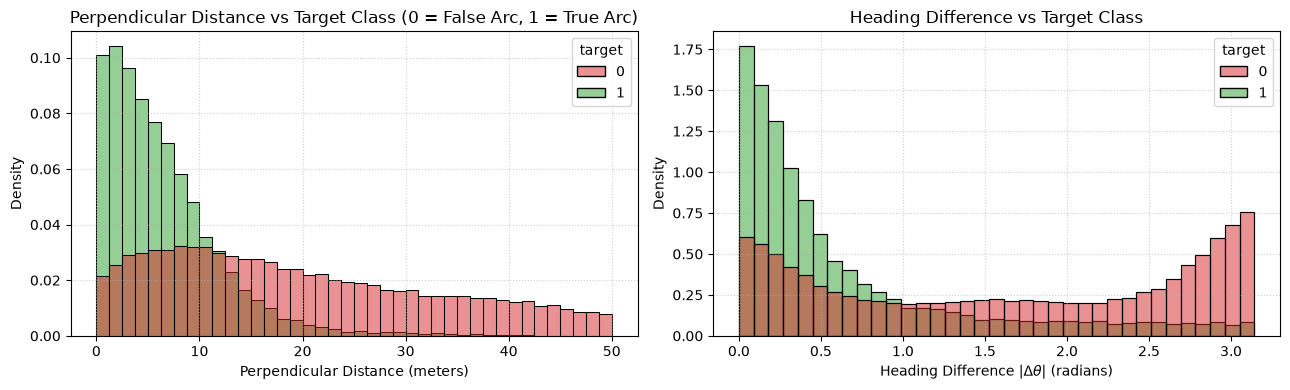

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# 1. Perpendicular Distance distribution by target class
sns.histplot(
    data=test_df[test_df["perp_dist"] <= 50],
    x="perp_dist",
    hue="target",
    bins=40,
    stat="density",
    common_norm=False,
    ax=axes[0],
    palette={0: "#d62728", 1: "#2ca02c"}
)
axes[0].set_title("Perpendicular Distance vs Target Class (0 = False Arc, 1 = True Arc)")
axes[0].set_xlabel("Perpendicular Distance (meters)")
axes[0].grid(True, linestyle=":", alpha=0.6)

# 2. Heading Difference distribution by target class
sns.histplot(
    data=test_df,
    x="heading_diff",
    hue="target",
    bins=35,
    stat="density",
    common_norm=False,
    ax=axes[1],
    palette={0: "#d62728", 1: "#2ca02c"}
)
axes[1].set_title(r"Heading Difference vs Target Class")
axes[1].set_xlabel(r"Heading Difference $|\Delta \theta|$ (radians)")
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()
